In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
qc_a = QuantumCircuit(2, 2)

qc_a.h(0)
qc_a.cx(0, 1)

qc_a.measure([0, 1], [0, 1])

print("Part A: Correlated outcomes")
print(qc_a.draw())

job_a = simulator.run(transpile(qc_a, simulator), shots=100)
counts_a = job_a.result().get_counts()

print("Prediction: 00 and 11 should dominate")
print("Measurement results:", counts_a)

plot_histogram(counts_a, title="Part A - Correlated Outcomes")
plt.show()

Part A: Correlated outcomes
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
Prediction: 00 and 11 should dominate
Measurement results: {'11': 45, '00': 55}


In [3]:
qc_b = QuantumCircuit(2, 2)

qc_b.x(1)
qc_b.h(0)
qc_b.cx(0, 1)

qc_b.measure([0, 1], [0, 1])

print("Part B: Opposite outcomes")
print(qc_b.draw())

job_b = simulator.run(transpile(qc_b, simulator), shots=100)
counts_b = job_b.result().get_counts()

print("Prediction: 01 and 10 should dominate")
print("Measurement results:", counts_b)

plot_histogram(counts_b, title="Part B - Opposite Outcomes")
plt.show()

Part B: Opposite outcomes
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     ├───┤┌─┴─┐└╥┘┌─┐
q_1: ┤ X ├┤ X ├─╫─┤M├
     └───┘└───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
Prediction: 01 and 10 should dominate
Measurement results: {'10': 48, '01': 52}


In [4]:
plot_histogram(
    [counts_a, counts_b],
    legend=["Part A: Correlated", "Part B: Opposite"],
    title="Quantum Correlation Switch"
)
plt.show()

In [5]:
print("PART A - CORRELATED")
print("00:", counts_a.get("00", 0))
print("11:", counts_a.get("11", 0))
print("01:", counts_a.get("01", 0))
print("10:", counts_a.get("10", 0))

print("\nPART B - OPPOSITE")
print("00:", counts_b.get("00", 0))
print("11:", counts_b.get("11", 0))
print("01:", counts_b.get("01", 0))
print("10:", counts_b.get("10", 0))

PART A - CORRELATED
00: 55
11: 45
01: 0
10: 0

PART B - OPPOSITE
00: 0
11: 0
01: 52
10: 48


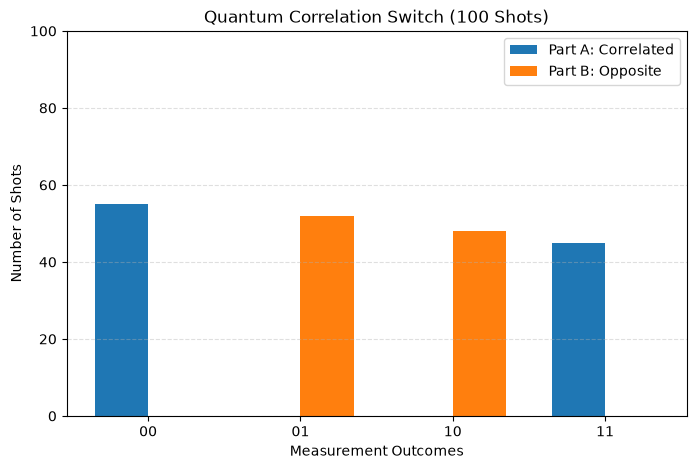

In [6]:
import matplotlib.pyplot as plt
import numpy as np

outcomes = ['00', '01', '10', '11']

part_a = [counts_a.get(x, 0) for x in outcomes]
part_b = [counts_b.get(x, 0) for x in outcomes]

x = np.arange(len(outcomes))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, part_a, width, label='Part A: Correlated')
plt.bar(x + width/2, part_b, width, label='Part B: Opposite')

plt.xlabel('Measurement Outcomes')
plt.ylabel('Number of Shots')
plt.title('Quantum Correlation Switch (100 Shots)')
plt.xticks(x, outcomes)
plt.ylim(0, 100)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.show()